rumz
# Notebook for processing ice
### March 25
#### V. 3.1.2
- Updated to match spectralBubbles V. 1.1.2

This notebook processes hyperspectral images of ice and extracts information in regards to climate proxies.
To run:
- ensure datasetPath points to the correct directory file
- Insert DataID for whichever core to be run

In [1]:
import warnings
import sys
import os
import matplotlib.pyplot as plt

# Add the processing folder to the Python path
processing_path = os.path.abspath(os.path.join('..', 'processing'))
if processing_path not in sys.path:
    sys.path.append(processing_path)

#Importing Python Libraries and Packages
import pandas as pd
import numpy as np
import set_icespec_path as tool
import set_bubbles_path as tool2
icespec_code_path=tool.add_icespec_code_dir()
bubble_code_path=tool2.add_bubble_code_dir()
tool.add_icespec_code_dir()
tool2.add_bubble_code_dir()
from icespec import icespec_process2_module as processice
from bubbles import bubbles_process_module as processbubbles
from icespec import savePNG

### Users should fill in variables with desired core info
Use HSI_July2024 Spreadsheet for ID and section names

Debug variable prints more information during processing

In [2]:
datasetPath = '/data/icecores/HSI_2024.csv' #path to csv file on computer or server

outputDir = '/data/icecores/Output' #output path

DataID = "HSIUM-87" #insert DataID from excel file inside quotation marks

Debug = True

In [3]:
dataPath, top_depth, bottom_depth, core_length, save_path, px_dims, metadata = processice.getDataPath(datasetPath, DataID, outputDir)

outputPath = f"{save_path}/"
print("Output Path: ", outputPath)
#os.makedirs(outputPath, exist_ok=True)

%matplotlib ipympl
data_nparr, w_ref, d_ref, fwhm = processice.getEnviData(dataPath)

Core:  ALHIC 2302
Section:  34 Sec 40
Lighting: Top light - 100%, Bottom Light - 0%
Exposure:  16
Top Depth:  30.72
Bottom Depth:  31.67
Length =  0.9500000000000028
Dimensions:  1800, 7000, 100, 880
Output Path:  /data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-34/


In [4]:
#segment_boundaries, cm_per_pixel = processbubbles.get_segments(data_nparr, top_depth, bottom_depth, end_px=7100)
#print("cm per px: ", cm_per_pixel)

#dataSize = [1500, 6600, 200, 900] #fill in based on interactive plot
dataSize = px_dims
stdSize = [530, 820, 200, 900] #standard sizing

/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)


Reflectance calculated. Dimensions: (5200, 680, 224)
Shape After:  (5200, 680, 1)


ValueError: n_components=3 must be between 0 and min(n_samples, n_features)=1 with svd_solver='covariance_eigh'

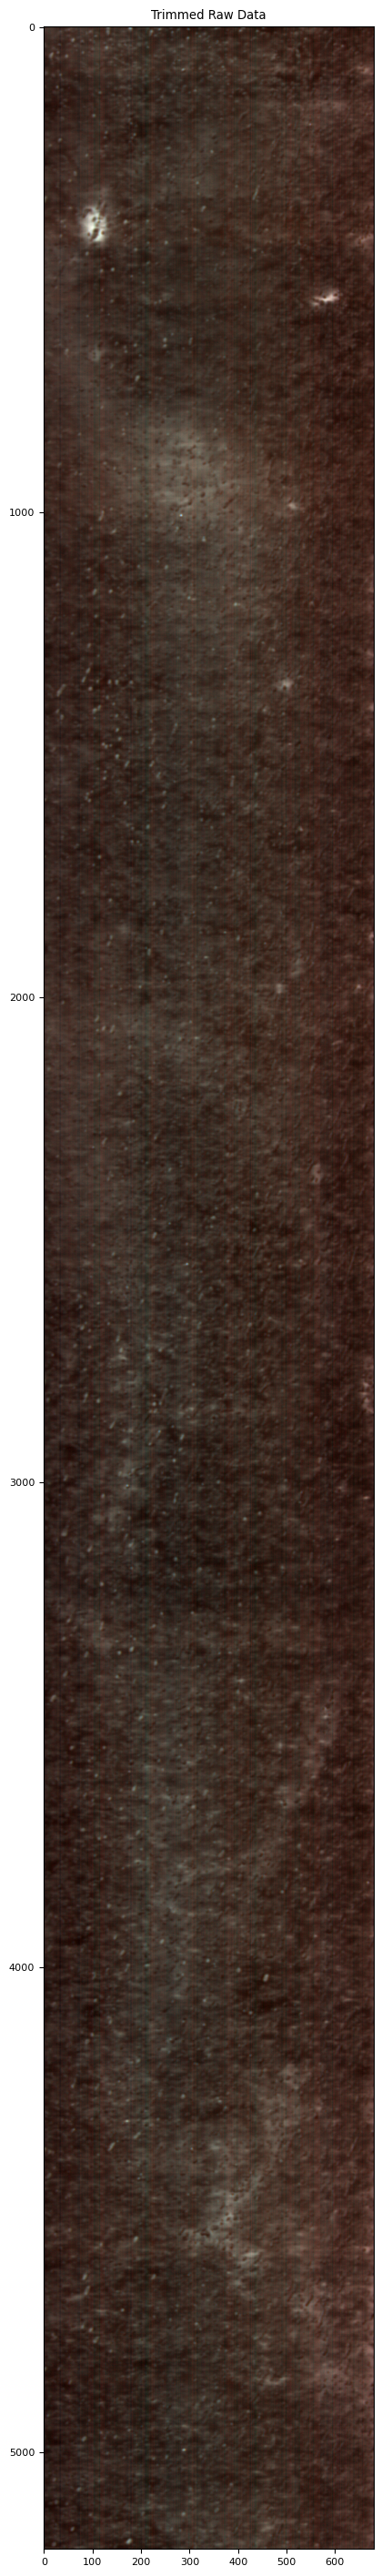

In [5]:
%matplotlib inline

trimmedData = processice.trim(data_nparr, w_ref, d_ref, dataSize, stdSize, Debug=False) #return arr of 3 trimmed
correctedData = processice.reflectance(trimmedData, Debug)
correctedData = np.clip(correctedData, 0, None)
filtered_img, fwhm = processice.remove_bands(correctedData, trimmedData[1], fwhm)
#previewed_img = processice.previewImg(filtered_img, "Filtered Image")
inpainted_img = processice.bubbles(filtered_img, fwhm)
flattened_img = processice.flatten_data(inpainted_img)

rematrix_img = processice.resize_matrix(flattened_img, trimmedData, pc_num = 3) #pc_num can be changed

eq_img = processice.equalize(rematrix_img, save=False, savePath=f"{outputPath}{DataID}_equalizedImages_{DataID.split("-")[1]}.png")